<a href="https://colab.research.google.com/github/snape0931/Epileptic-Seizure-Detection/blob/main/sop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install EMD-signal scipy numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [EMD-signal]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from PyEMD import EMD

In [2]:
!git clone https://github.com/snape0931/Epileptic-Seizure-Detection.git
!pip install -q EMD-signal vmdpy antropy

fatal: destination path 'Epileptic-Seizure-Detection' already exists and is not an empty directory.


In [3]:
import numpy as np, pandas as pd
from pathlib import Path

DATA_DIR = Path("Epileptic-Seizure-Detection/DATASET")
FS = 173.61
SET_MAP = {"Z": "A", "O": "B", "N": "C", "F": "D", "S": "E"}
GROUP = {"A": "Normal", "B": "Normal", "C": "Interictal", "D": "Interictal", "E": "Seizure"}

signals, sets = [], []
for f in sorted(p for p in DATA_DIR.rglob("*") if p.suffix.lower() == ".txt"):
    s = SET_MAP.get(f.stem[0].upper())
    if s is None:
        continue
    signals.append(np.loadtxt(f)[:4096])
    sets.append(s)

X = np.array(signals)
sets = np.array(sets)
y = np.array([GROUP[s] for s in sets])
print(X.shape)                       # expect (500, 4096)
print(pd.Series(sets).value_counts().sort_index())

(500, 4096)
A    100
B    100
C    100
D    100
E    100
Name: count, dtype: int64


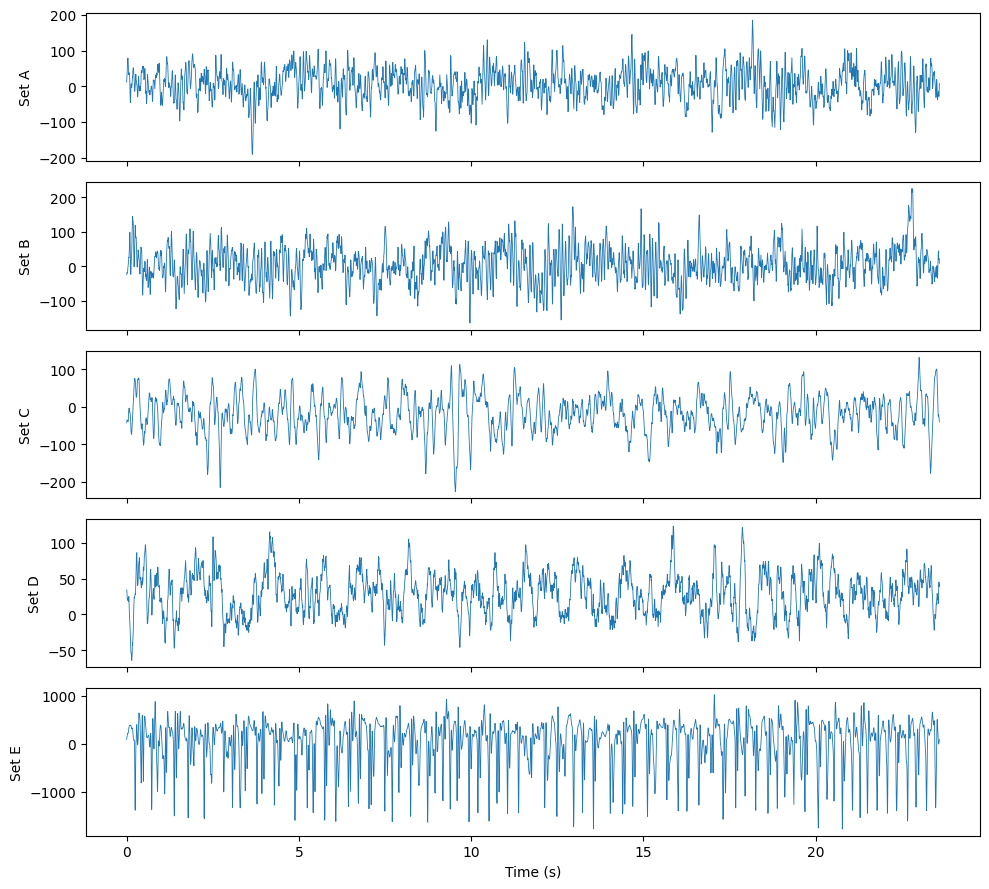

In [4]:
import matplotlib.pyplot as plt
t = np.arange(4096) / FS
fig, ax = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
for a, s in zip(ax, "ABCDE"):
    a.plot(t, X[sets == s][0], lw=0.6)
    a.set_ylabel(f"Set {s}")
plt.xlabel("Time (s)"); plt.tight_layout(); plt.show()

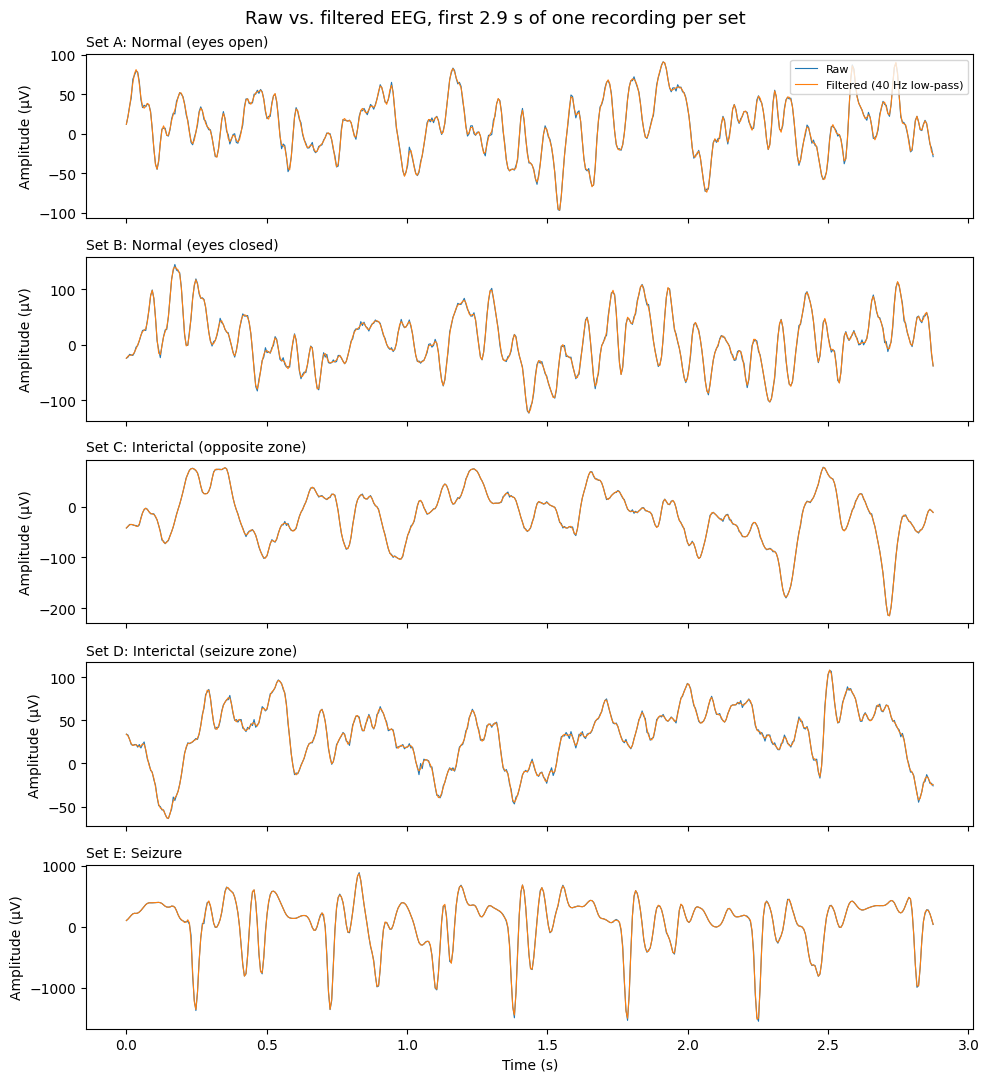

In [5]:
from scipy.signal import butter, filtfilt
b, a = butter(4, 40, btype="low", fs=FS)
Xf = filtfilt(b, a, X, axis=1)

names = {"A": "Set A: Normal (eyes open)", "B": "Set B: Normal (eyes closed)",
         "C": "Set C: Interictal (opposite zone)", "D": "Set D: Interictal (seizure zone)",
         "E": "Set E: Seizure"}

fig, ax = plt.subplots(5, 1, figsize=(10, 11), sharex=True)
for a_, s in zip(ax, "ABCDE"):
    i = np.where(sets == s)[0][0]
    a_.plot(t[:500], X[i][:500], lw=0.8, label="Raw")
    a_.plot(t[:500], Xf[i][:500], lw=0.8, label="Filtered (40 Hz low-pass)")
    a_.set_title(names[s], fontsize=10, loc="left")
    a_.set_ylabel("Amplitude (µV)")
ax[0].legend(loc="upper right", fontsize=8)
ax[-1].set_xlabel("Time (s)")
fig.suptitle("Raw vs. filtered EEG, first 2.9 s of one recording per set", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
!pip install -q EMD-signal vmdpy pysdkit

In [8]:
import time
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.signal import decimate
from PyEMD import EMD
from vmdpy import VMD
from pysdkit import MVMD


# ---------------- settings ----------------
K = 6                 # modes kept per signal (same for all three methods)
TOL = 1e-6            # convergence tolerance (looser = faster)
DOWNSAMPLE = False    # True halves the length (4096 -> 2048) for ~2x speed
# ------------------------------------------

if DOWNSAMPLE and Xf.shape[1] == 4096:      # only downsample once
    Xf = decimate(Xf, 2, axis=1)
    FS = FS / 2
T = Xf.shape[1]
t = np.arange(T) / FS
letters, C = "ABCDE", 5
idx = {s: np.where(sets == s)[0] for s in letters}

def pad(modes, K):
    modes = np.asarray(modes)[:K]
    if len(modes) < K:
        modes = np.vstack([modes, np.zeros((K - len(modes), modes.shape[1]))])
    return modes

# ---------------- 1. EMD ----------------
t0 = time.time()
modes_emd = np.zeros((len(Xf), K, T))
for i, x in enumerate(tqdm(Xf, desc="EMD")):
    modes_emd[i] = pad(EMD().emd(x, max_imf=K), K)[:, :T]
np.save("modes_emd.npy", modes_emd)
print(f"EMD  done in {time.time()-t0:.0f}s", modes_emd.shape)

# ---------------- 2. VMD ----------------
t0 = time.time()
modes_vmd = np.zeros((len(Xf), K, T))
for i, x in enumerate(tqdm(Xf, desc="VMD")):
    u, _, omega = VMD(x, 2000, 0, K, 0, 1, TOL)    # alpha, tau, K, DC, init, tol
    u = u[np.argsort(omega[-1])]                   # sort modes slow -> fast
    modes_vmd[i] = u[:, :T]
np.save("modes_vmd.npy", modes_vmd)
print(f"VMD  done in {time.time()-t0:.0f}s", modes_vmd.shape)


EMD:   0%|          | 0/500 [00:00<?, ?it/s]

EMD  done in 71s (500, 6, 4096)


VMD:   0%|          | 0/500 [00:00<?, ?it/s]

VMD  done in 836s (500, 6, 4096)


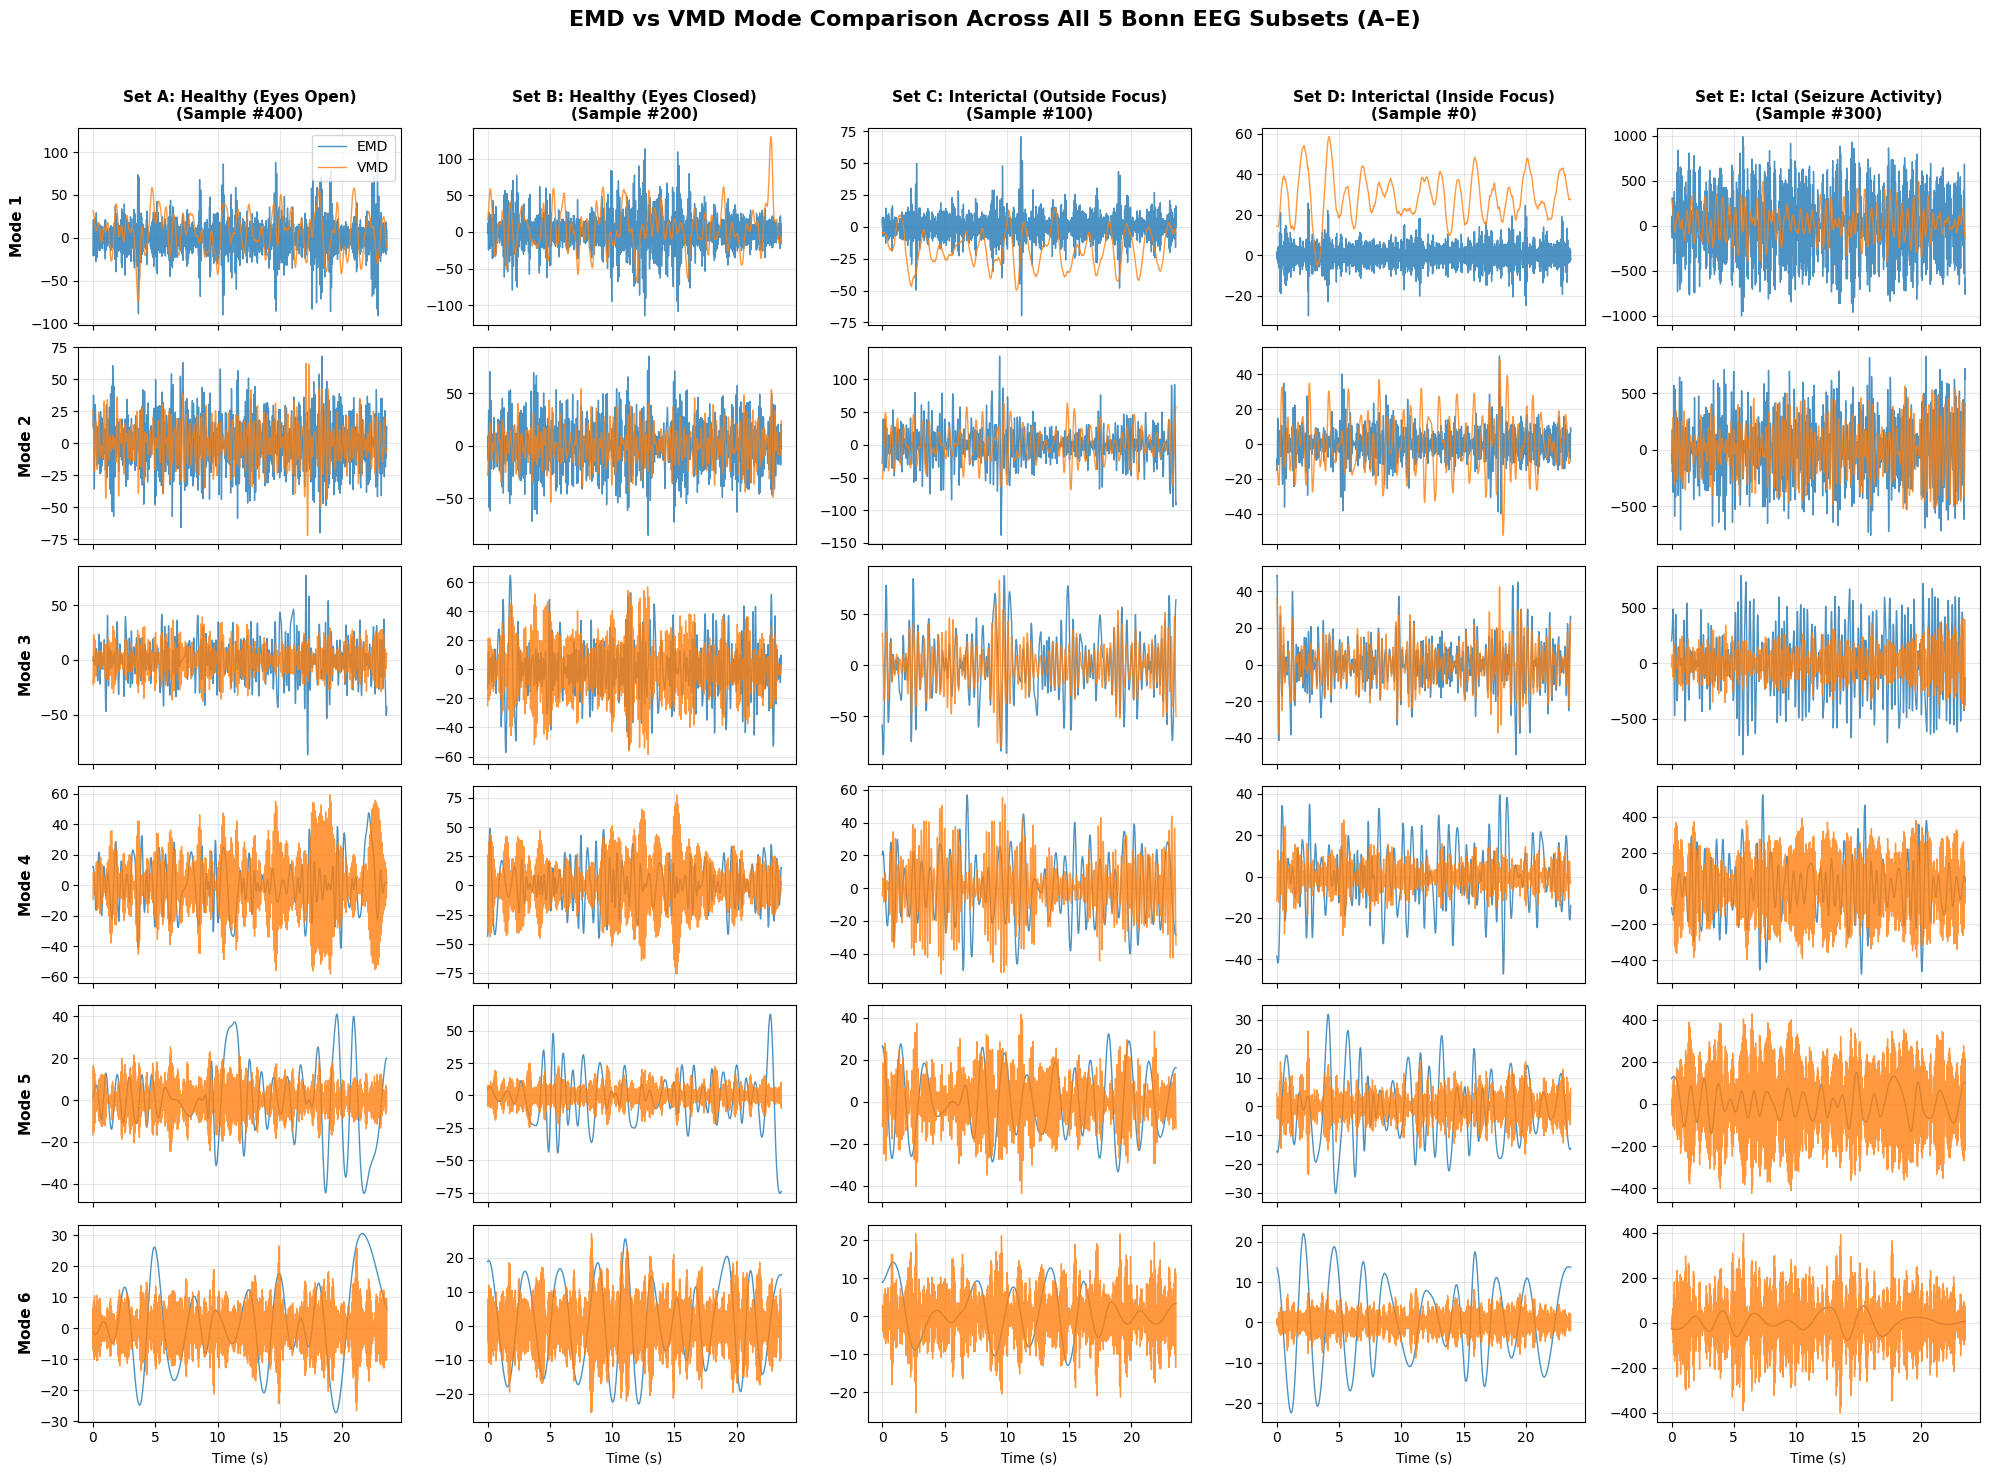

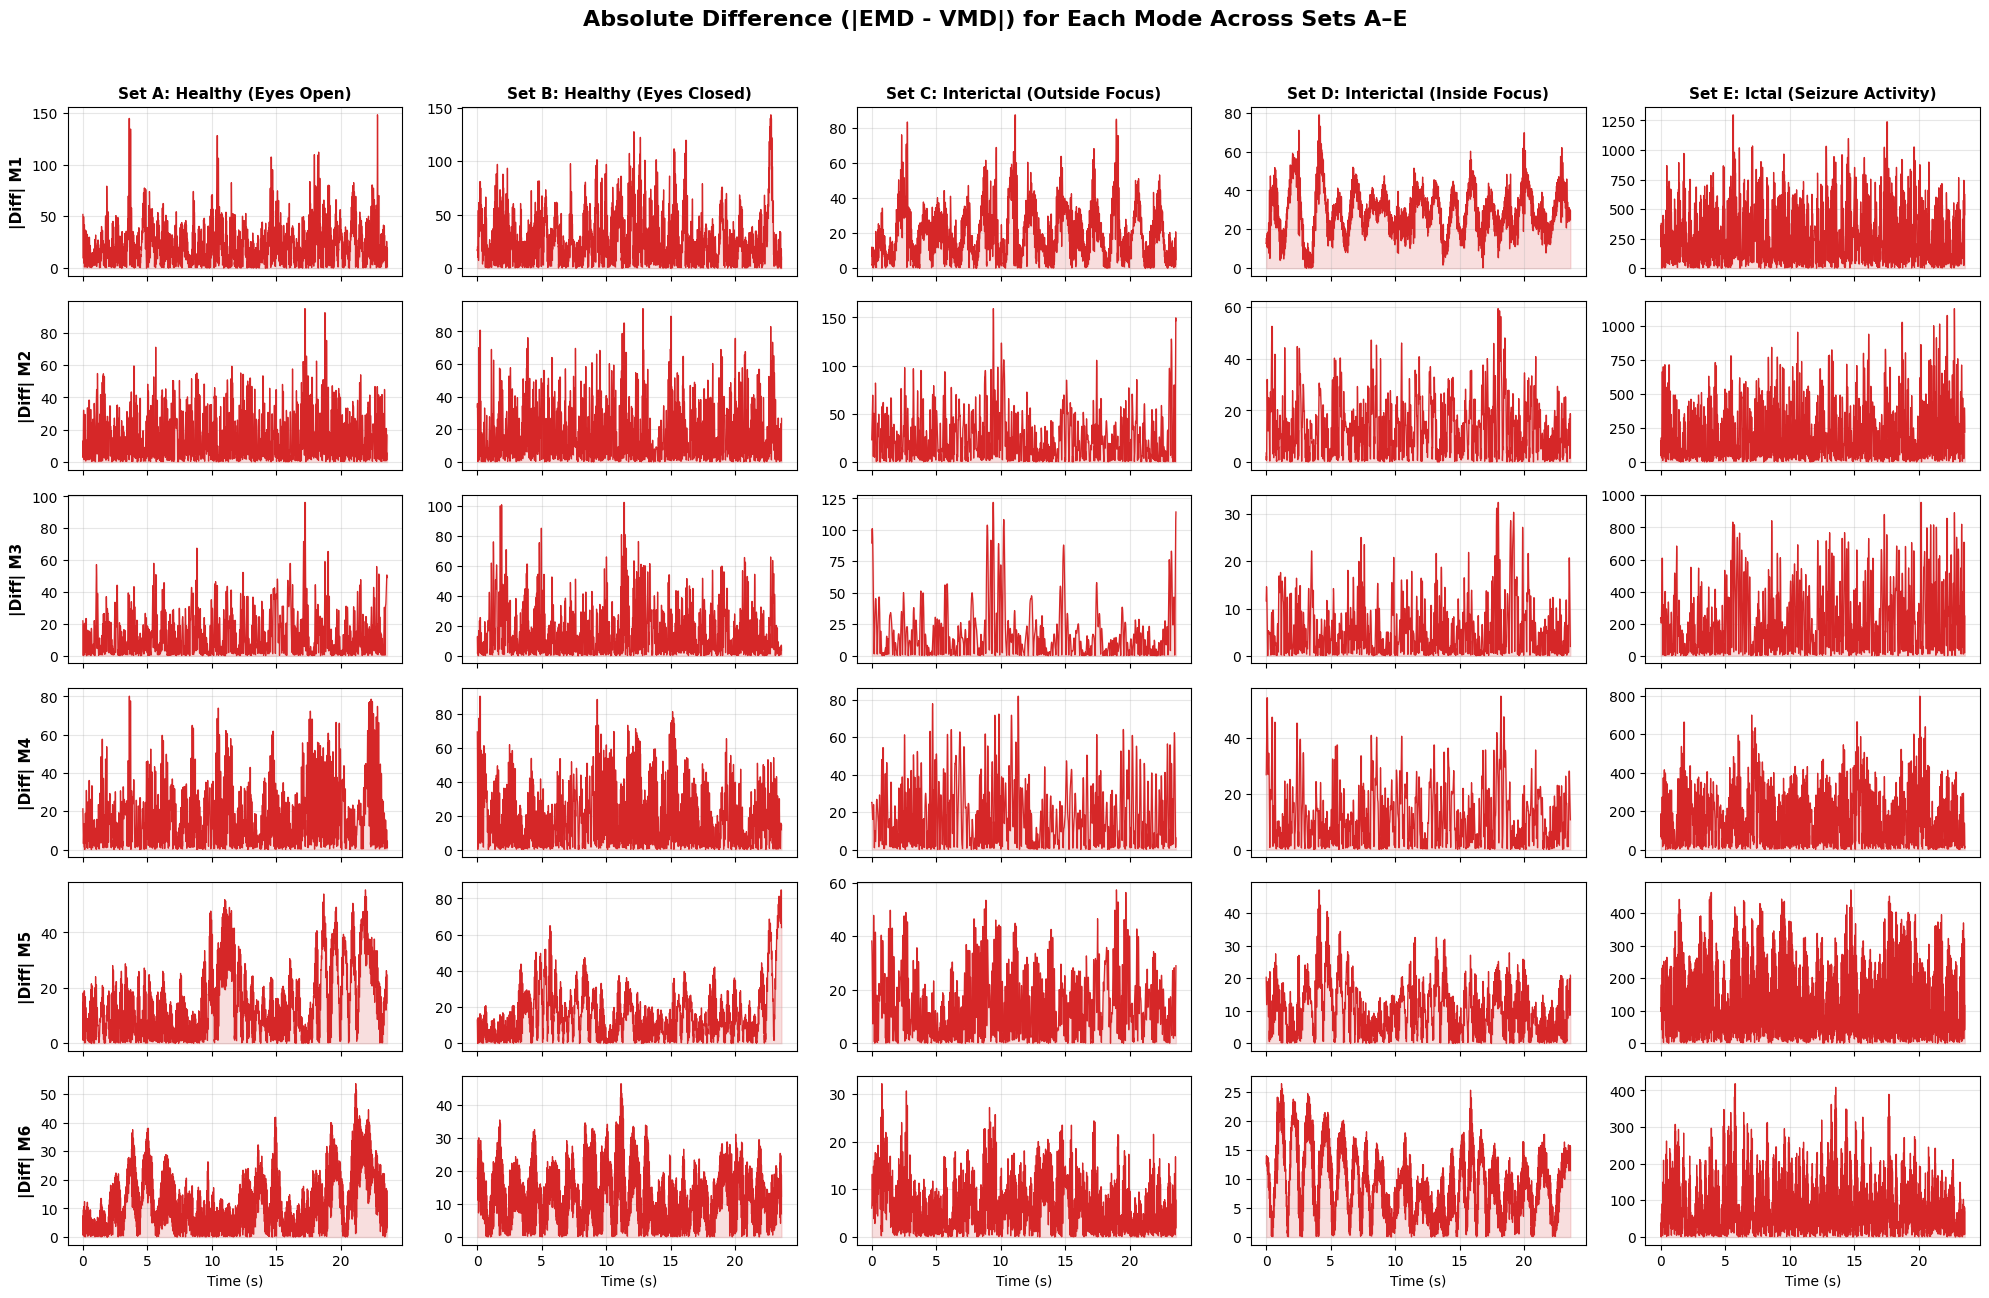


Bonn Set   | Mean MSE     | Mean Correlation   | Energy Ratio (VMD/EMD)
Set A      | 563.44979    | 0.0722             | 1.1113              
Set B      | 1299.93159   | 0.0705             | 0.9638              
Set C      | 857.65254    | 0.1032             | 0.9453              
Set D      | 2257.29960   | 0.0933             | 0.7322              
Set E      | 33141.48031  | 0.0940             | 0.5626              


In [9]:
letters = ["A", "B", "C", "D", "E"]
set_titles = {
    "A": "Set A: Healthy (Eyes Open)",
    "B": "Set B: Healthy (Eyes Closed)",
    "C": "Set C: Interictal (Outside Focus)",
    "D": "Set D: Interictal (Inside Focus)",
    "E": "Set E: Ictal (Seizure Activity)"
}

# Select the first sample from each set
sample_indices = {s: idx[s][0] for s in letters}

# --- GRAPH 1: Representative Comparison (All 5 Sets Side-by-Side) ---
fig, axes = plt.subplots(K, 5, figsize=(20, 2.5 * K), sharex=True)
fig.suptitle("EMD vs VMD Mode Comparison Across All 5 Bonn EEG Subsets (A–E)", fontsize=16, fontweight='bold')

for col, s in enumerate(letters):
    s_idx = sample_indices[s]
    axes[0, col].set_title(f"{set_titles[s]}\n(Sample #{s_idx})", fontsize=11, fontweight='bold')

    for k in range(K):
        ax = axes[k, col]

        # Signal waveforms
        emd_mode = modes_emd[s_idx, k]
        vmd_mode = modes_vmd[s_idx, k]

        ax.plot(t, emd_mode, label="EMD", color="tab:blue", alpha=0.8, linewidth=1)
        ax.plot(t, vmd_mode, label="VMD", color="tab:orange", alpha=0.8, linewidth=1)

        if col == 0:
            ax.set_ylabel(f"Mode {k+1}", fontsize=11, fontweight='bold')
        if k == 0 and col == 0:
            ax.legend(loc="upper right")

        ax.grid(True, alpha=0.3)

for col in range(5):
    axes[-1, col].set_xlabel("Time (s)", fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("bonn_all5_sets_modes.png", dpi=300)
plt.show()

# --- GRAPH 2: Absolute Difference Graph (|EMD - VMD|) Across All 5 Sets ---
fig, axes = plt.subplots(K, 5, figsize=(20, 2.2 * K), sharex=True)
fig.suptitle("Absolute Difference (|EMD - VMD|) for Each Mode Across Sets A–E", fontsize=16, fontweight='bold')

for col, s in enumerate(letters):
    s_idx = sample_indices[s]
    axes[0, col].set_title(f"{set_titles[s]}", fontsize=11, fontweight='bold')

    for k in range(K):
        ax = axes[k, col]
        diff = np.abs(modes_emd[s_idx, k] - modes_vmd[s_idx, k])

        ax.plot(t, diff, color="tab:red", linewidth=0.9)
        ax.fill_between(t, 0, diff, color="tab:red", alpha=0.15)

        if col == 0:
            ax.set_ylabel(f"|Diff| M{k+1}", fontsize=11, fontweight='bold')
        ax.grid(True, alpha=0.3)

for col in range(5):
    axes[-1, col].set_xlabel("Time (s)", fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("bonn_all5_sets_difference.png", dpi=300)
plt.show()
# 4. QUANTITATIVE DIFFERENCE METRICS ACROSS ALL 5 SETS
print("\n" + "="*70)
print(f"{'Bonn Set':<10} | {'Mean MSE':<12} | {'Mean Correlation':<18} | {'Energy Ratio (VMD/EMD)':<20}")
print("="*70)

for s in letters:
    s_indices = idx[s]

    # Extract subsets
    sub_emd = modes_emd[s_indices]  # [100, K, T]
    sub_vmd = modes_vmd[s_indices]  # [100, K, T]

    # 1. Mean Squared Error (MSE)
    mse = np.mean((sub_emd - sub_vmd) ** 2)

    # 2. Pearson Correlation coefficient per mode averaged over samples
    corrs = []
    for i in range(len(s_indices)):
        for k in range(K):
            c = np.corrcoef(sub_emd[i, k], sub_vmd[i, k])[0, 1]
            if not np.isnan(c):
                corrs.append(c)
    mean_corr = np.mean(corrs)

    # 3. Energy ratio sum(VMD^2) / sum(EMD^2)
    energy_emd = np.sum(sub_emd ** 2)
    energy_vmd = np.sum(sub_vmd ** 2)
    energy_ratio = energy_vmd / (energy_emd + 1e-12)

    print(f"Set {s:<6} | {mse:<12.5f} | {mean_corr:<18.4f} | {energy_ratio:<20.4f}")

print("="*70)

**Set A (Healthy, Eyes Open):** EMD and VMD show broadly similar fluctuations across most modes, with some noticeable amplitude differences and occasional spikes.

**Set B (Healthy, Eyes Closed):** Both methods capture similar oscillatory patterns in several modes, although differences in peak amplitudes and waveform shapes are visible.

**Set C (Interictal, Outside Focus):** Differences are evident in several modes, particularly Mode 1, where VMD exhibits larger negative excursions at certain time points.

**Set D (Interictal, Inside Focus):** Mode 1 shows a prominent difference: VMD produces sustained positive oscillations, whereas EMD fluctuates around zero. Other modes show comparatively closer overlap in several intervals.

**Set E (Ictal, Seizure Activity):** amplitude fluctuations are visible, especially in Modes 1–3. EMD and VMD differ in the amplitude and temporal structure of several extracted components.

**Across all five sets:** The agreement between EMD and VMD varies by mode and EEG subset; the corresponding modes do not consistently overlap.

**Overall observation:** The graph indicates that EMD and VMD represent the EEG signals differently, with particularly noticeable differences in Set D, Mode 1, and the higher-amplitude fluctuations in Set E. These visual observations alone do not establish which method is better for seizure detection

